# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
%pip install numpy pandas matplotlib scikit-learn tabulate seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os

print("SUSY.csv exists:", os.path.exists("SUSY.csv"))
print("SUSY-small.csv exists:", os.path.exists("SUSY-small.csv"))

SUSY.csv exists: True
SUSY-small.csv exists: True


In [3]:
import os
import time
import gzip
import shutil
import requests

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz"

compressed_file = "SUSY.csv.gz"
dataset_file = "SUSY.csv"

download_success = False

for attempt in range(1, 6):
    try:
        print(f"Download attempt {attempt}/5")

        # Start a fresh download each time
        with requests.get(
            url,
            stream=True,
            timeout=(30, 300),
            headers={"User-Agent": "Mozilla/5.0"}
        ) as response:

            response.raise_for_status()

            with open(compressed_file, "wb") as f:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)

        # Verify the entire compressed file
        print("Checking compressed file...")

        with gzip.open(compressed_file, "rb") as f:
            while f.read(8 * 1024 * 1024):
                pass

        download_success = True
        print("Download verified!")
        break

    except Exception as error:
        print("Download or verification failed:", error)

        for filename in [compressed_file, dataset_file]:
            if os.path.exists(filename):
                os.remove(filename)

        if attempt < 5:
            print("Retrying in 10 seconds...")
            time.sleep(10)

if download_success:
    print("Extracting dataset. Please wait...")

    with gzip.open(compressed_file, "rb") as source:
        with open(dataset_file, "wb") as destination:
            shutil.copyfileobj(source, destination)

    print("Extraction complete!")
    print("Dataset path:", os.path.abspath(dataset_file))
    print("Uncompressed size:",
          round(os.path.getsize(dataset_file) / (1024**3), 2), "GB")

else:
    print("The download failed after 5 attempts.")
    print("Do not try extracting the incomplete file.")

Download attempt 1/5
Checking compressed file...
Download verified!
Extracting dataset. Please wait...
Extraction complete!
Dataset path: /home/Aohenewaa/Data-3402/DATA3402.Fall.2026/Labs/Lab.7/SUSY.csv
Uncompressed size: 2.23 GB


In [4]:
import pandas as pd
import os

dataset_file = "SUSY.csv"

print("Dataset exists:", os.path.exists(dataset_file))
print("File size:", round(os.path.getsize(dataset_file) / (1024**3), 2), "GB")

# Load only the first 100,000 rows to test it
df = pd.read_csv(dataset_file, header=None, nrows=100_000)

print("Dataset loaded successfully!")
print("Rows and columns in sample:", df.shape)

display(df.head())

Dataset exists: True
File size: 2.23 GB
Dataset loaded successfully!
Rows and columns in sample: (100000, 19)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859


In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nData types:")
print(df.dtypes)
print("\nSummary statistics:")
display(df.describe())

Missing values per column:
0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
dtype: int64

Data types:
0     float64
1     float64
2     float64
3     float64
4     float64
5     float64
6     float64
7     float64
8     float64
9     float64
10    float64
11    float64
12    float64
13    float64
14    float64
15    float64
16    float64
17    float64
18    float64
dtype: object

Summary statistics:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
count,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,1.000000e+05
mean,0.45975,1.002520,-0.001214,0.001130,0.998765,-0.002327,0.001986,1.002132,-0.001027,1.001774e+00,0.001874,1.001381,1.000968,0.998835,1.002564,1.000301,1.002018,0.996392,2.255094e-01
std,0.49838,0.682332,1.005256,1.003296,0.649669,1.004957,1.000790,0.876802,1.001608,8.878220e-01,1.005287,0.624153,0.584931,0.471350,0.860436,0.616290,0.624171,0.436301,1.977076e-01
min,0.00000,0.255649,-2.102649,-1.734744,0.428590,-2.059240,-1.733849,0.000709,-1.727112,9.238942e-07,-10.582791,0.272967,0.009538,0.018478,0.000000,0.074357,0.004657,0.000008,2.388670e-07
25%,0.00000,0.563566,-0.764006,-0.868199,0.595844,-0.775816,-0.864801,0.480474,-0.865236,3.711455e-01,-0.491849,0.589816,0.620144,0.649552,0.169395,0.598758,0.515733,0.685564,6.905427e-02
50%,0.00000,0.792447,-0.001697,0.000985,0.798784,-0.003995,0.002508,0.775232,-0.013274,8.020215e-01,-0.078552,0.828958,0.879155,0.933930,0.906571,0.835261,0.917300,1.089616,1.681940e-01
75%,1.00000,1.209686,0.762437,0.872140,1.160556,0.769450,0.867590,1.207878,0.869245,1.373204e+00,0.352210,1.213489,1.222236,1.279828,1.615310,1.209476,1.385430,1.366626,3.303397e-01
max,1.00000,12.620587,2.101403,1.734717,13.107124,2.059317,1.734670,13.959188,1.740672,1.450629e+01,14.342724,13.969072,13.200295,5.335464,12.791473,14.024200,10.329440,1.591660,1.000000e+00


In [6]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [7]:
#!rm SUSY.csv

In [8]:
#!gunzip SUSY.csv.gz

In [9]:
ls -lh

total 3.4G
-rw-r--r-- 1 Aohenewaa Aohenewaa 357K Oct 15 20:39 Lab.7.ipynb
-rw-r--r-- 1 Aohenewaa Aohenewaa 150K Oct 15 20:39 Lab.7.pdf
-rw-r--r-- 1 Aohenewaa Aohenewaa  71K Oct 23 15:13 Lab.7.solution.ipynb
-rw-r--r-- 1 Aohenewaa Aohenewaa 228M Oct 23 12:38 SUSY-small.csv
-rw-r--r-- 1 Aohenewaa Aohenewaa 2.3G Oct 23 15:13 SUSY.csv
-rw-r--r-- 1 Aohenewaa Aohenewaa 880M Oct 23 15:13 SUSY.csv.gz


The data is provided as a comma separated file.

In [10]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [11]:
!ls -lh

total 3.4G
-rw-r--r-- 1 Aohenewaa Aohenewaa 357K Oct 15 20:39 Lab.7.ipynb
-rw-r--r-- 1 Aohenewaa Aohenewaa 150K Oct 15 20:39 Lab.7.pdf
-rw-r--r-- 1 Aohenewaa Aohenewaa  71K Oct 23 15:13 Lab.7.solution.ipynb
-rw-r--r-- 1 Aohenewaa Aohenewaa 228M Oct 23 12:38 SUSY-small.csv
-rw-r--r-- 1 Aohenewaa Aohenewaa 2.3G Oct 23 15:13 SUSY.csv
-rw-r--r-- 1 Aohenewaa Aohenewaa 880M Oct 23 15:13 SUSY.csv.gz


We see that we have 5 million datapoints.

In [12]:
!wc -l SUSY.csv

5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [13]:
!head -500000 SUSY.csv > SUSY-small.csv

In [14]:
ls -lh

total 3.4G
-rw-r--r-- 1 Aohenewaa Aohenewaa 357K Oct 15 20:39 Lab.7.ipynb
-rw-r--r-- 1 Aohenewaa Aohenewaa 150K Oct 15 20:39 Lab.7.pdf
-rw-r--r-- 1 Aohenewaa Aohenewaa  71K Oct 23 15:13 Lab.7.solution.ipynb
-rw-r--r-- 1 Aohenewaa Aohenewaa 228M Oct 23 15:14 SUSY-small.csv
-rw-r--r-- 1 Aohenewaa Aohenewaa 2.3G Oct 23 15:13 SUSY.csv
-rw-r--r-- 1 Aohenewaa Aohenewaa 880M Oct 23 15:13 SUSY.csv.gz


In [15]:
! wc -l SUSY-small.csv

500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [16]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [17]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [18]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [19]:
FeatureNames

['MET_rel',
 'S_R',
 'R',
 'MT2',
 'M_Delta_R',
 'cos_theta_r1',
 'axial_MET',
 'dPhi_r_b',
 'M_TR_2',
 'M_R']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [21]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [22]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [23]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


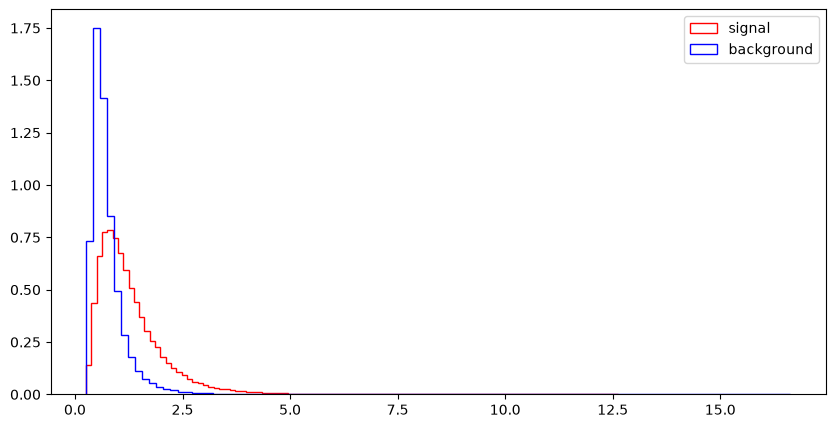

l_1_eta


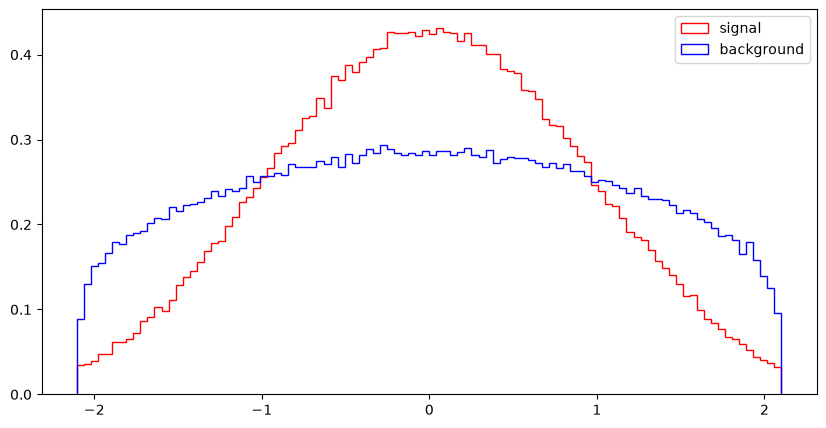

l_1_phi


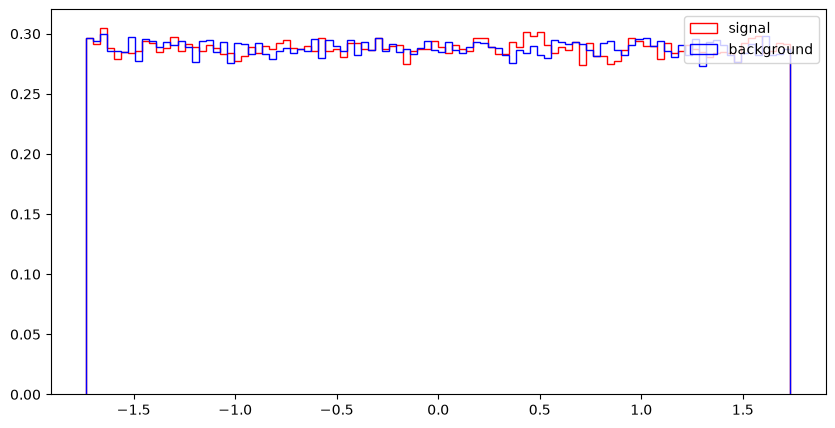

l_2_pT


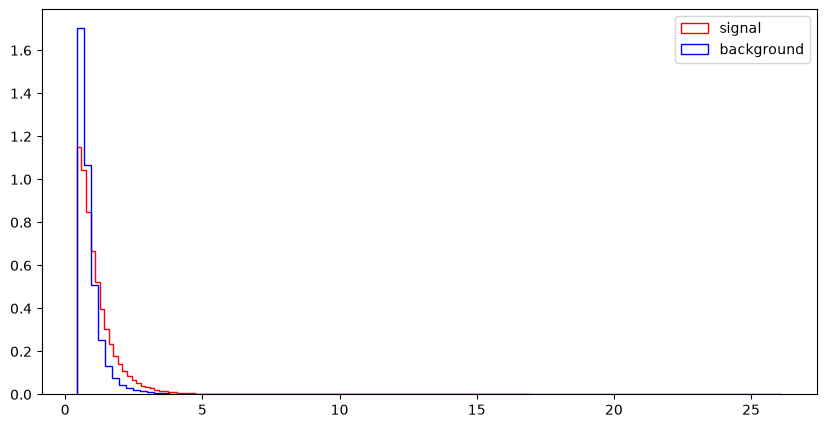

l_2_eta


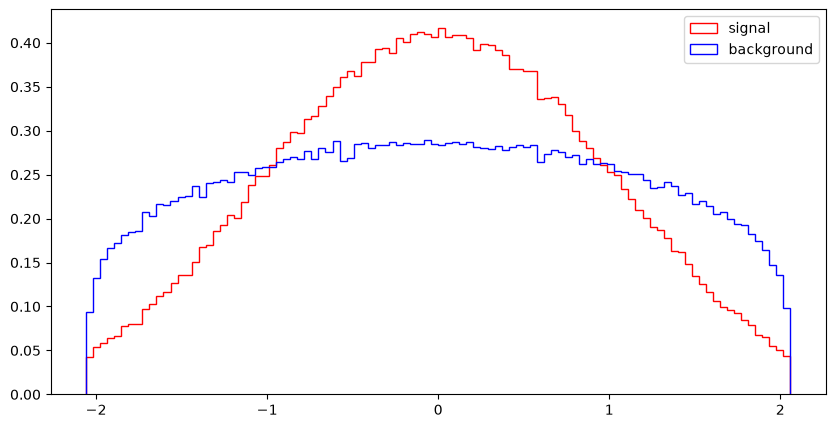

l_2_phi


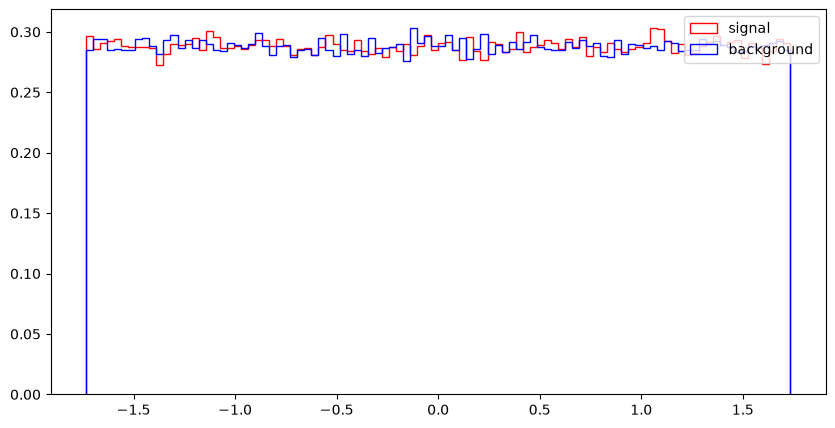

MET


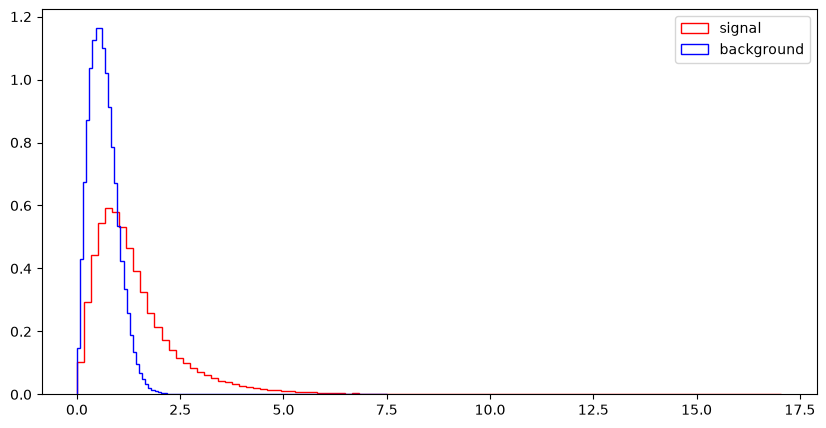

MET_phi


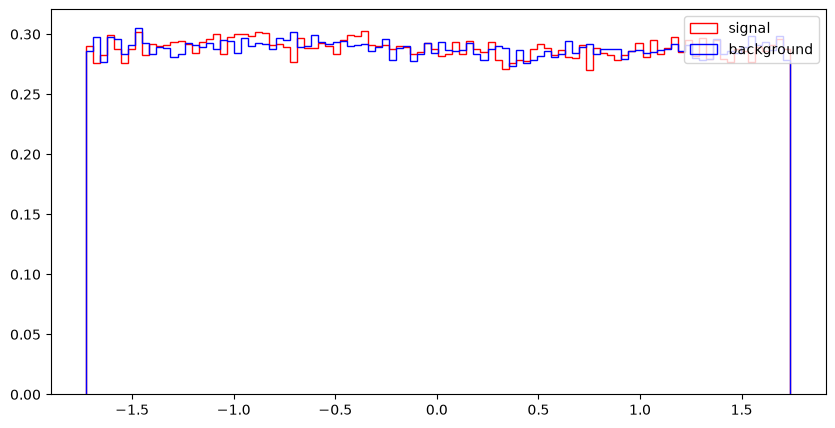

MET_rel


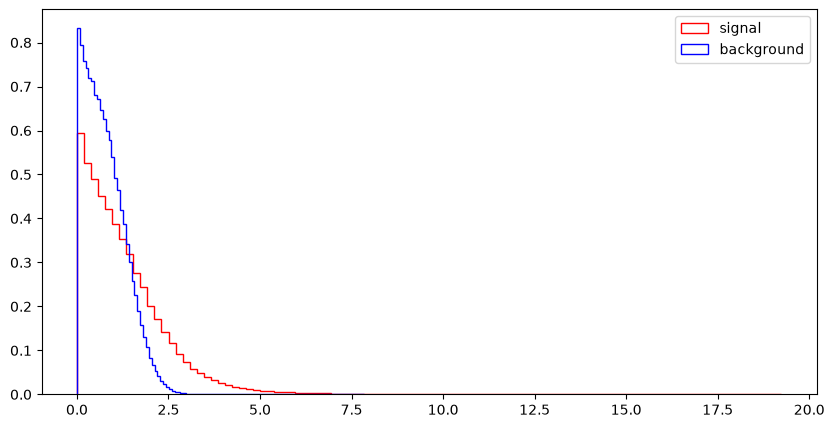

axial_MET


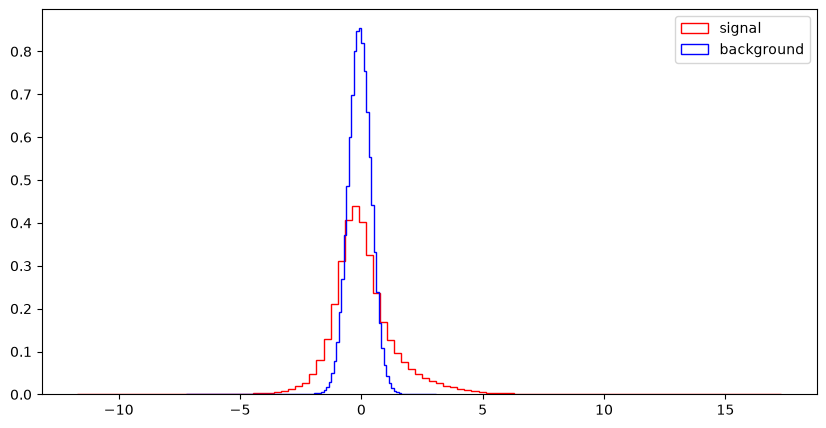

M_R


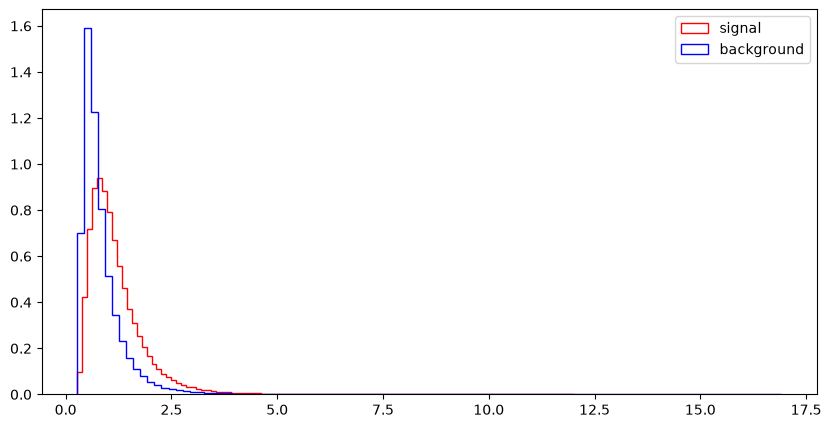

M_TR_2


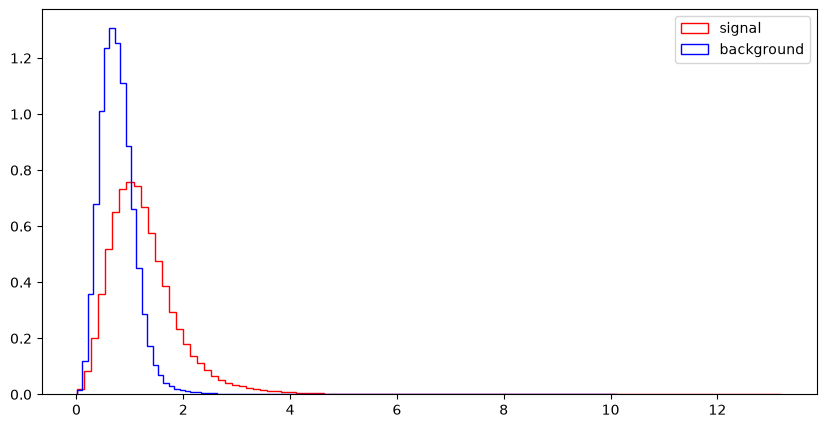

R


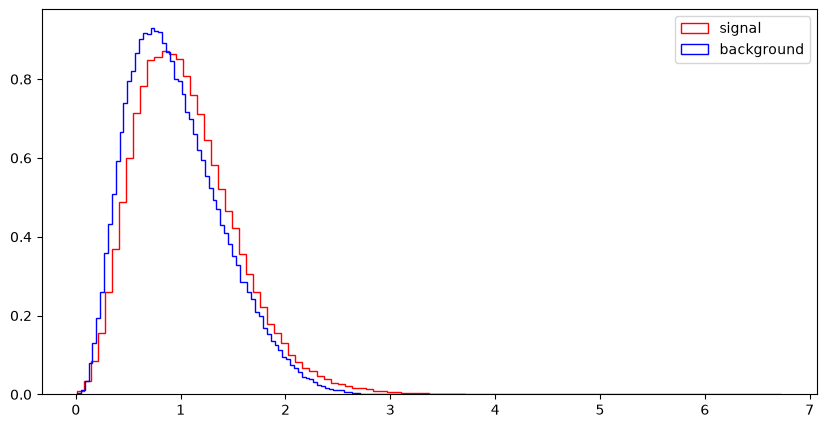

MT2


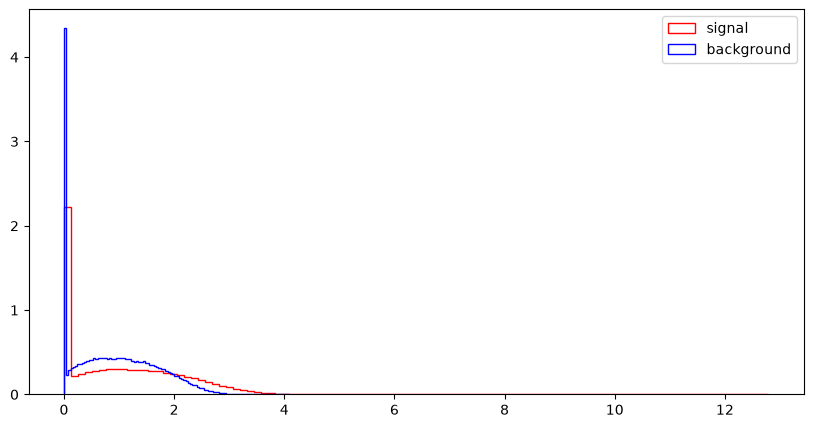

S_R


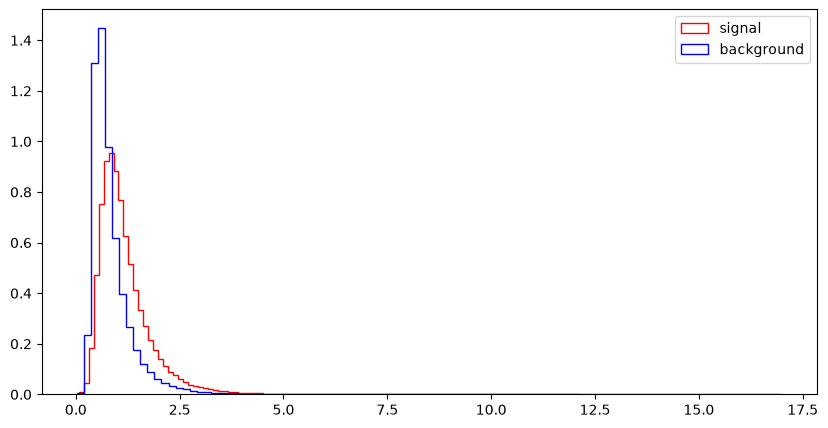

M_Delta_R


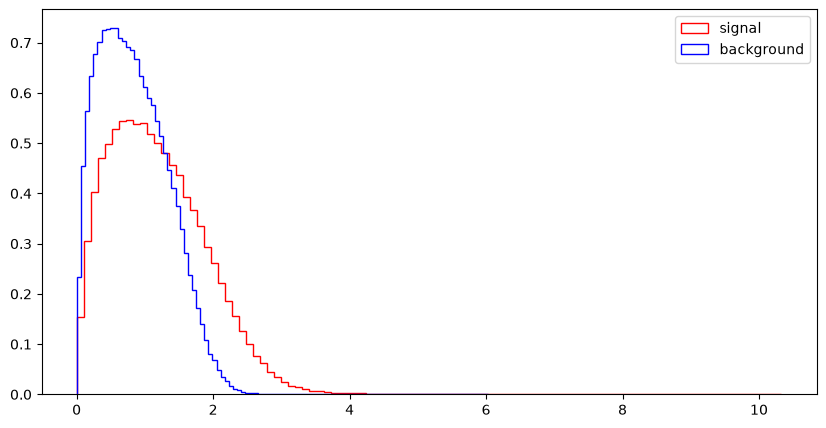

dPhi_r_b


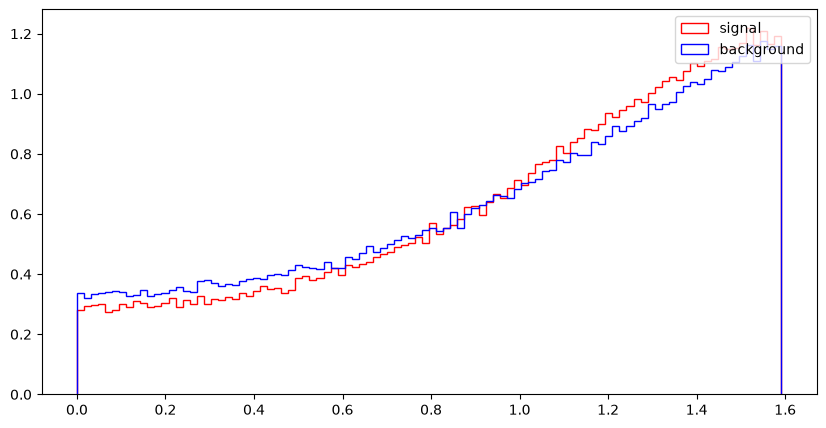

cos_theta_r1


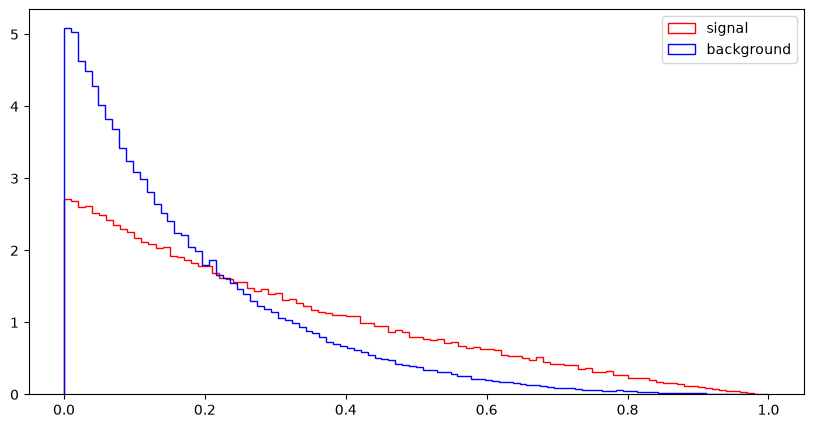

In [24]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

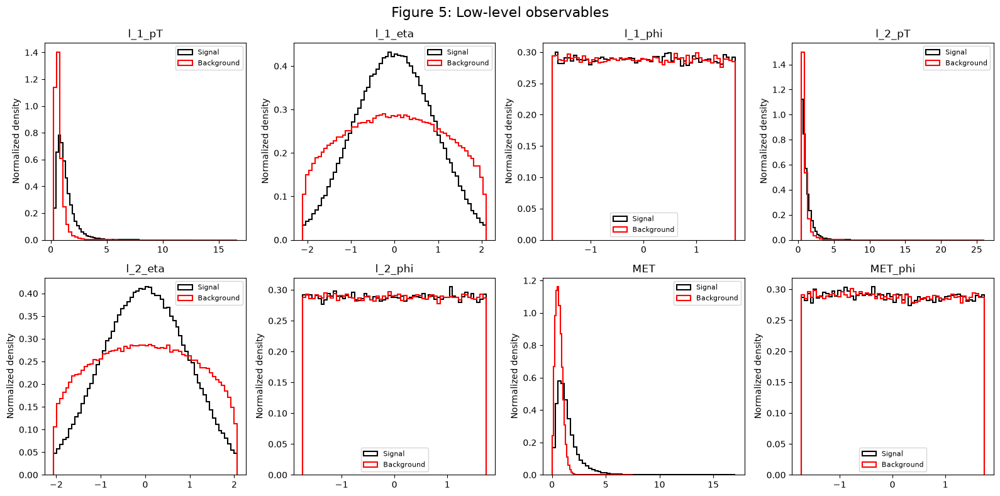

In [25]:
import numpy as np
import matplotlib.pyplot as plt

low_level = RawNames

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, var in zip(axes, low_level):
    ax.hist(
        df_sig[var], bins=60, density=True,
        histtype="step", color="black", linewidth=1.5,
        label="Signal"
    )
    ax.hist(
        df_bkg[var], bins=60, density=True,
        histtype="step", color="red", linewidth=1.5,
        label="Background"
    )

    ax.set_title(var)
    ax.set_ylabel("Normalized density")
    ax.legend(fontsize=8)

fig.suptitle("Figure 5: Low-level observables", fontsize=16)
plt.tight_layout()
plt.show()

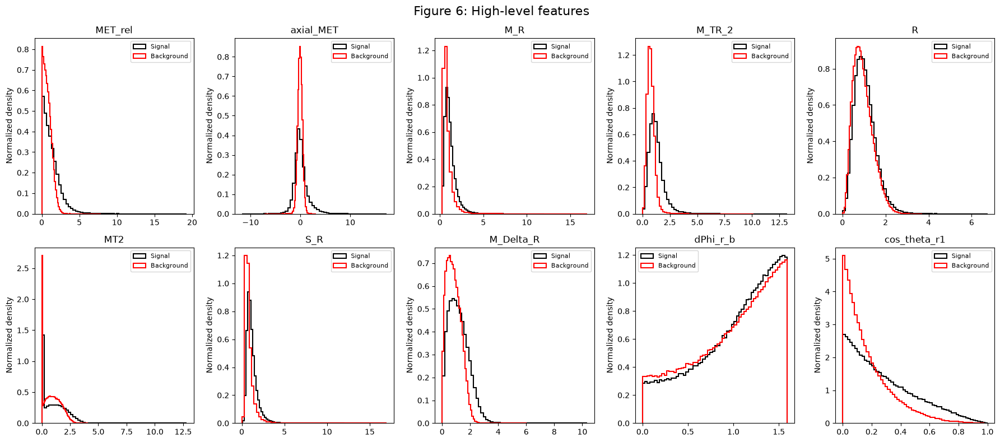

In [26]:
high_level = [var for var in VarNames[1:] if var not in RawNames]

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for ax, var in zip(axes, high_level):
    ax.hist(
        df_sig[var], bins=60, density=True,
        histtype="step", color="black", linewidth=1.5,
        label="Signal"
    )
    ax.hist(
        df_bkg[var], bins=60, density=True,
        histtype="step", color="red", linewidth=1.5,
        label="Background"
    )

    ax.set_title(var)
    ax.set_ylabel("Normalized density")
    ax.legend(fontsize=8)

fig.suptitle("Figure 6: High-level features", fontsize=16)
plt.tight_layout()
plt.show()

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

In [27]:
# 4.1a

import numpy as np
import matplotlib.pyplot as plt

def make_pair_plot(data_signal, data_background, variables,
                   sample_size=1500, bins=30, seed=42):
    """
    Create pair plots comparing signal and background.
    Uses a random sample to improve speed.
    """
    rng = np.random.default_rng(seed)

    n_signal = min(sample_size, len(data_signal))
    n_background = min(sample_size, len(data_background))

    signal = data_signal[variables].sample(
        n=n_signal, random_state=seed
    )
    background = data_background[variables].sample(
        n=n_background, random_state=seed
    )

    n_vars = len(variables)
    fig, axes = plt.subplots(
        n_vars, n_vars,
        figsize=(2.2 * n_vars, 2.2 * n_vars)
    )

    for i, y_var in enumerate(variables):
        for j, x_var in enumerate(variables):
            ax = axes[i, j]

            if i == j:
                ax.hist(
                    signal[x_var], bins=bins,
                    density=True, histtype="step",
                    color="black", label="Signal"
                )
                ax.hist(
                    background[x_var], bins=bins,
                    density=True, histtype="step",
                    color="red", label="Background"
                )
            else:
                ax.scatter(
                    background[x_var], background[y_var],
                    s=3, alpha=0.2, color="red",
                    label="Background"
                )
                ax.scatter(
                    signal[x_var], signal[y_var],
                    s=3, alpha=0.2, color="black",
                    label="Signal"
                )

            if i == 0:
                ax.set_title(x_var, fontsize=9)
            if j == 0:
                ax.set_ylabel(y_var, fontsize=9)

            ax.tick_params(axis="both", labelsize=7)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right")
    fig.suptitle("Pair plots: Signal vs. Background", y=1.01)
    plt.tight_layout()
    plt.show()


Low-level variables: 8


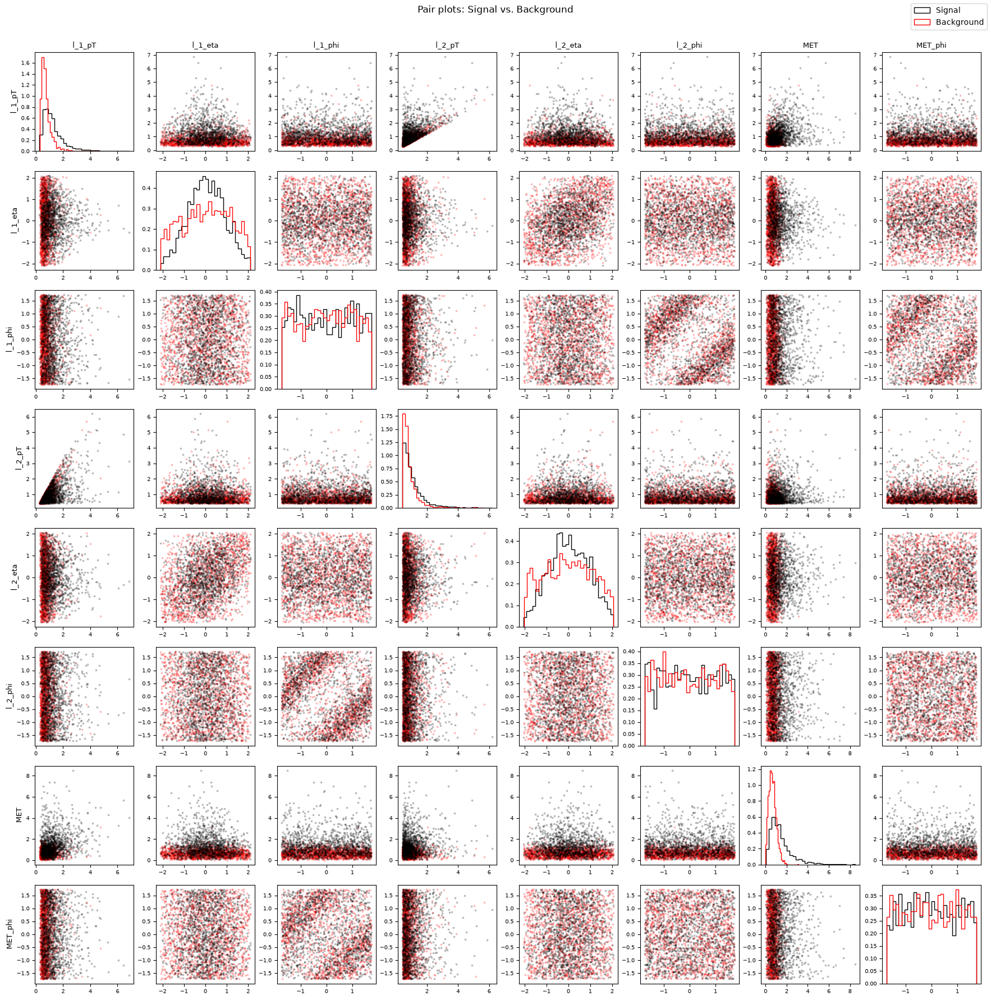

High-level variables: 10


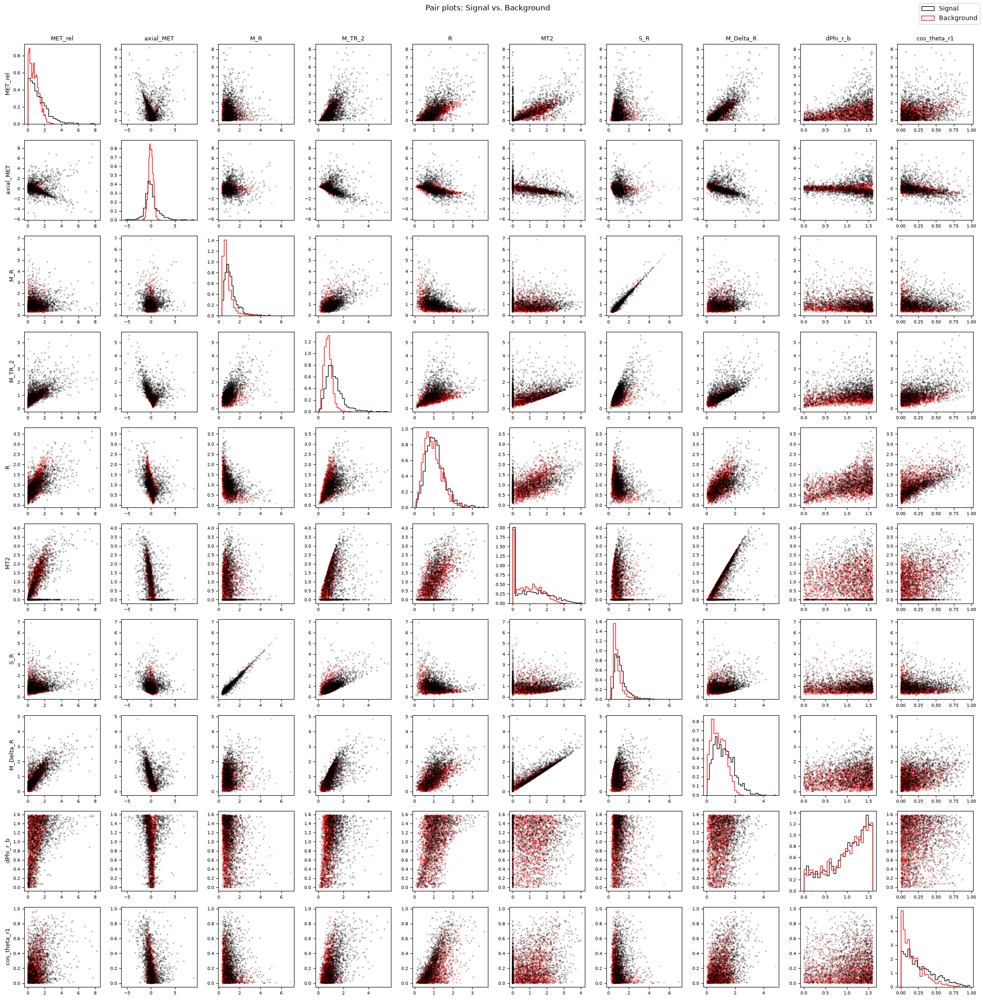

In [28]:

low_level = RawNames
high_level = [
    var for var in VarNames[1:]
    if var not in RawNames
]

print("Low-level variables:", len(low_level))
make_pair_plot(df_sig, df_bkg, low_level)

print("High-level variables:", len(high_level))
make_pair_plot(df_sig, df_bkg, high_level)


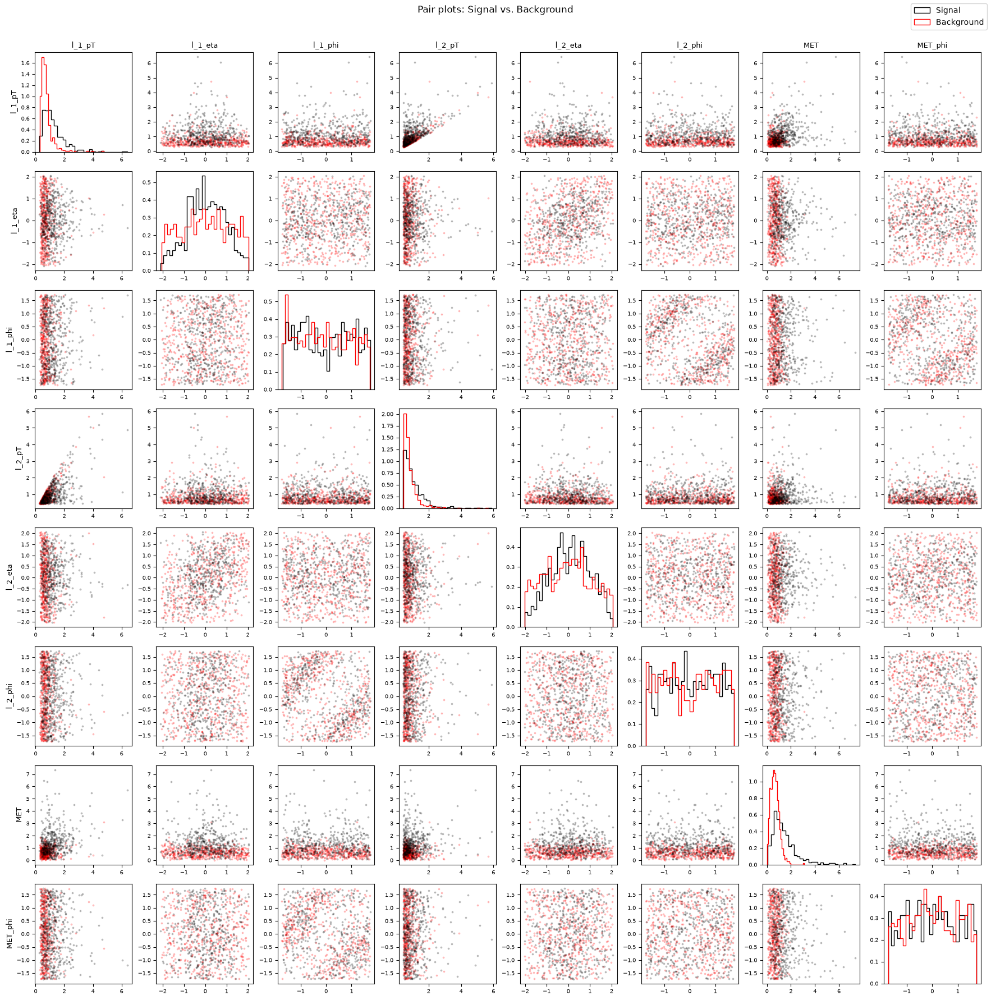

In [29]:
# 4.1b : Replacing the off-diagonal scatter plots with hist2d() or a binned-density plot. 
#This groups points into bins instead of drawing every point individually.

make_pair_plot(df_sig, df_bkg, RawNames, sample_size=500)


4.1c
Low-level variables: l_1_pT, l_2_pT, and MET show visible differences between signal and background distributions.

High-level variables: MET_rel, M_R, M_TR_2, R, MT2, and M_Delta_R show some separation, although the distributions still overlap.

Strong relationships: Several high-level variables have clear correlations. For example, M_R and S_R appear almost perfectly linearly related, and MT2 and M_Delta_R also show a strong relationship.

Limited separation: Variables such as l_1_phi, l_2_phi, and MET_phi have heavily overlapping distributions, so they appear less useful for separating the classes individually.

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [30]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


In [31]:

import numpy as np
import pandas as pd

all_observables = VarNames[1:]

low_level = RawNames
high_level = [v for v in all_observables if v not in RawNames]

def calculate_matrices(data, variables):
    """Calculate covariance and correlation matrices."""
    values = data[variables].to_numpy(dtype=float)

    covariance = np.cov(values, rowvar=False)
    correlation = np.corrcoef(values, rowvar=False)

    return covariance, correlation

cov_all, corr_all = calculate_matrices(df, all_observables)
cov_low, corr_low = calculate_matrices(df, low_level)
cov_high, corr_high = calculate_matrices(df, high_level)

print("All observables:", cov_all.shape, corr_all.shape)
print("Low-level observables:", cov_low.shape, corr_low.shape)
print("High-level features:", cov_high.shape, corr_high.shape)


All observables: (18, 18) (18, 18)
Low-level observables: (8, 8) (8, 8)
High-level features: (10, 10) (10, 10)


In [32]:
#4.2c
from IPython.display import HTML, display
from tabulate import tabulate

def display_matrix(matrix, variables, title, digits=3):
    """Display a labeled matrix as an HTML table."""
    table = []

    for variable, row in zip(variables, matrix):
        table.append(
            [variable] + [f"{value:.{digits}f}" for value in row]
        )

    html_table = tabulate(
        table,
        headers=["Variable"] + variables,
        tablefmt="html"
    )

    display(HTML(f"<h4>{title}</h4>" + html_table))

display_matrix(corr_all, all_observables, "Correlation: All observables")
display_matrix(corr_low, low_level, "Correlation: Low-level observables")
display_matrix(corr_high, high_level, "Correlation: High-level features")

display_matrix(cov_all, all_observables, "Covariance: All observables")
display_matrix(cov_low, low_level, "Covariance: Low-level observables")
display_matrix(cov_high, high_level, "Covariance: High-level features")


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001,0.16,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0,-0.001,-0.002,-0.002,0.002
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002,-0.001,0.078,0.797,0.43,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0,0.001,-0.001,-0.001,0,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1,-0.005,-0,-0.002,-0.002,-0,0,-0.003,-0.001,-0.004,0.001
MET_rel,0.16,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272
M_R,0.078,0.027,1,0.577,-0.383,-0.068,0.981,0.189,-0.106,-0.116
M_TR_2,0.584,-0.317,0.577,1,0.38,0.379,0.635,0.668,0.229,0.451
R,0.595,-0.383,-0.383,0.38,1,0.574,-0.287,0.564,0.424,0.627
MT2,0.535,-0.535,-0.068,0.379,0.574,1,-0.021,0.809,0.056,0.264
S_R,0.15,-0.067,0.981,0.635,-0.287,-0.021,1,0.249,-0.013,-0.085
M_Delta_R,0.748,-0.373,0.189,0.668,0.564,0.809,0.249,1,0.155,0.319
dPhi_r_b,0.378,-0.057,-0.106,0.229,0.424,0.056,-0.013,0.155,1,0.106
cos_theta_r1,0.316,-0.272,-0.116,0.451,0.627,0.264,-0.085,0.319,0.106,1


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001,0.098,-0.01,0.364,0.287,-0.06,-0.012,0.343,0.098,-0.047,0.022
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,0,0,-0.001,-0.001,-0.001,0
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185,0.001,-0.002,0.001,0.001,0,0.001,0.001,0.001,0.001,0
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002,-0.001,0.051,0.325,0.163,-0.099,-0.069,0.322,0.006,-0.004,-0.028
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0,0.001,-0.001,-0.001,0,0,0.001,-0.001,0.001,-0,0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035,0.001,-0.002,0.001,0.001,0.001,0.002,0.001,0.001,-0,0
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.073
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003,-0.005,-0,-0.001,-0.001,-0,0,-0.002,-0.001,-0.002,0
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.01,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054
M_R,0.044,0.017,0.392,0.21,-0.113,-0.037,0.38,0.074,-0.029,-0.014
M_TR_2,0.302,-0.185,0.21,0.338,0.104,0.189,0.228,0.242,0.058,0.052
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.083,0.165,0.087,0.058
MT2,0.409,-0.461,-0.037,0.189,0.232,0.738,-0.011,0.433,0.021,0.045
S_R,0.082,-0.041,0.38,0.228,-0.083,-0.011,0.382,0.096,-0.003,-0.01
M_Delta_R,0.415,-0.233,0.074,0.242,0.165,0.433,0.096,0.389,0.042,0.039
dPhi_r_b,0.146,-0.025,-0.029,0.058,0.087,0.021,-0.003,0.042,0.19,0.009
cos_theta_r1,0.055,-0.054,-0.014,0.052,0.058,0.045,-0.01,0.039,0.009,0.039


In [33]:
# 4.1d
def analyze_observables(data, variables, title):
    """Calculate and display covariance and correlation matrices."""
    covariance, correlation = calculate_matrices(data, variables)

    display_matrix(
        covariance, variables,
        f"{title} — Covariance Matrix"
    )

    display_matrix(
        correlation, variables,
        f"{title} — Correlation Matrix"
    )

    return covariance, correlation

cov_all, corr_all = analyze_observables(
    df, all_observables, "All Observables"
)

cov_low, corr_low = analyze_observables(
    df, low_level, "Low-Level Observables"
)

cov_high, corr_high = analyze_observables(
    df, high_level, "High-Level Features"
)


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001,0.098,-0.01,0.364,0.287,-0.06,-0.012,0.343,0.098,-0.047,0.022
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,0,0,-0.001,-0.001,-0.001,0
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185,0.001,-0.002,0.001,0.001,0,0.001,0.001,0.001,0.001,0
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002,-0.001,0.051,0.325,0.163,-0.099,-0.069,0.322,0.006,-0.004,-0.028
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0,0.001,-0.001,-0.001,0,0,0.001,-0.001,0.001,-0,0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035,0.001,-0.002,0.001,0.001,0.001,0.002,0.001,0.001,-0,0
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.073
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003,-0.005,-0,-0.001,-0.001,-0,0,-0.002,-0.001,-0.002,0
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.01,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001,0.16,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0,-0.001,-0.002,-0.002,0.002
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002,-0.001,0.078,0.797,0.43,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0,0.001,-0.001,-0.001,0,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1,-0.005,-0,-0.002,-0.002,-0,0,-0.003,-0.001,-0.004,0.001
MET_rel,0.16,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054
M_R,0.044,0.017,0.392,0.21,-0.113,-0.037,0.38,0.074,-0.029,-0.014
M_TR_2,0.302,-0.185,0.21,0.338,0.104,0.189,0.228,0.242,0.058,0.052
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.083,0.165,0.087,0.058
MT2,0.409,-0.461,-0.037,0.189,0.232,0.738,-0.011,0.433,0.021,0.045
S_R,0.082,-0.041,0.38,0.228,-0.083,-0.011,0.382,0.096,-0.003,-0.01
M_Delta_R,0.415,-0.233,0.074,0.242,0.165,0.433,0.096,0.389,0.042,0.039
dPhi_r_b,0.146,-0.025,-0.029,0.058,0.087,0.021,-0.003,0.042,0.19,0.009
cos_theta_r1,0.055,-0.054,-0.014,0.052,0.058,0.045,-0.01,0.039,0.009,0.039


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272
M_R,0.078,0.027,1,0.577,-0.383,-0.068,0.981,0.189,-0.106,-0.116
M_TR_2,0.584,-0.317,0.577,1,0.38,0.379,0.635,0.668,0.229,0.451
R,0.595,-0.383,-0.383,0.38,1,0.574,-0.287,0.564,0.424,0.627
MT2,0.535,-0.535,-0.068,0.379,0.574,1,-0.021,0.809,0.056,0.264
S_R,0.15,-0.067,0.981,0.635,-0.287,-0.021,1,0.249,-0.013,-0.085
M_Delta_R,0.748,-0.373,0.189,0.668,0.564,0.809,0.249,1,0.155,0.319
dPhi_r_b,0.378,-0.057,-0.106,0.229,0.424,0.056,-0.013,0.155,1,0.106
cos_theta_r1,0.316,-0.272,-0.116,0.451,0.627,0.264,-0.085,0.319,0.106,1


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

In [34]:

selection_strategy = {
    "l_1_pT": "greater",
    "l_1_eta": "inside",
    "l_1_phi": "greater",
    "l_2_pT": "greater",
    "l_2_eta": "inside",
    "l_2_phi": "greater",
    "MET": "greater",
    "MET_phi": "greater",
    "MET_rel": "greater",
    "axial_MET": "less",
    "M_R": "greater",
    "M_TR_2": "greater",
    "R": "greater",
    "MT2": "greater",
    "S_R": "greater",
    "M_Delta_R": "greater",
    "dPhi_r_b": "greater",
    "cos_theta_r1": "less",
}

print("Number of observables:", len(selection_strategy))
print("Strategies recorded:", len(selection_strategy) == 18)


Number of observables: 18
Strategies recorded: True


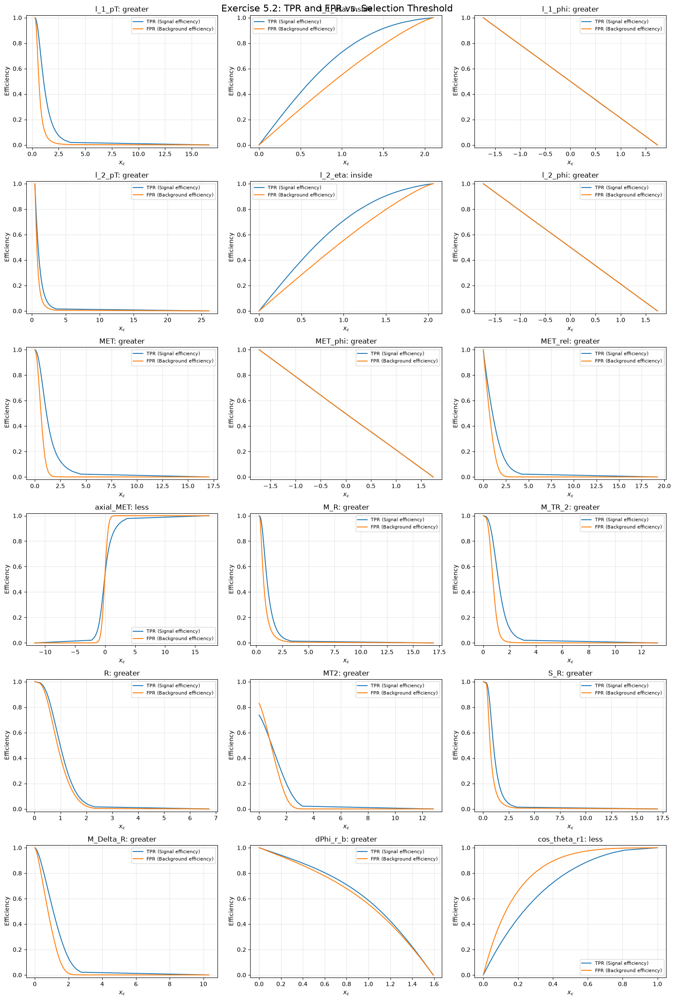

In [35]:

import numpy as np
import matplotlib.pyplot as plt

observables = VarNames[1:]

def calculate_efficiencies(signal, background, variable, strategy,
                            n_thresholds=100):
    s = signal[variable].to_numpy(dtype=float)
    b = background[variable].to_numpy(dtype=float)

    s = s[np.isfinite(s)]
    b = b[np.isfinite(b)]

    if strategy in ("inside", "outside"):
        mu = np.mean(np.concatenate([s, b]))
        s = np.abs(s - mu)
        b = np.abs(b - mu)

    pooled = np.concatenate([s, b])
    thresholds = np.unique(
        np.quantile(pooled, np.linspace(0, 1, n_thresholds))
    )

    if strategy in ("greater", "outside"):
        # Passing means value is strictly greater than threshold
        tpr = np.array([(s > t).mean() for t in thresholds])
        fpr = np.array([(b > t).mean() for t in thresholds])
    elif strategy in ("less", "inside"):
        # Passing means value is strictly less than threshold
        tpr = np.array([(s < t).mean() for t in thresholds])
        fpr = np.array([(b < t).mean() for t in thresholds])
    else:
        raise ValueError(f"Unknown strategy: {strategy}")

    return thresholds, tpr, fpr


fig, axes = plt.subplots(6, 3, figsize=(16, 24))
axes = axes.flatten()

efficiency_results = {}

for ax, variable in zip(axes, observables):
    strategy = selection_strategy[variable]

    thresholds, tpr, fpr = calculate_efficiencies(
        df_sig, df_bkg, variable, strategy
    )

    efficiency_results[variable] = {
        "thresholds": thresholds,
        "TPR": tpr,
        "FPR": fpr,
        "strategy": strategy
    }

    ax.plot(thresholds, tpr, label="TPR (Signal efficiency)")
    ax.plot(thresholds, fpr, label="FPR (Background efficiency)")
    ax.set_title(f"{variable}: {strategy}")
    ax.set_xlabel(r"$x_c$")
    ax.set_ylabel("Efficiency")
    ax.set_ylim(-0.02, 1.02)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle("Exercise 5.2: TPR and FPR vs. Selection Threshold",
             fontsize=16)
plt.tight_layout()
plt.show()


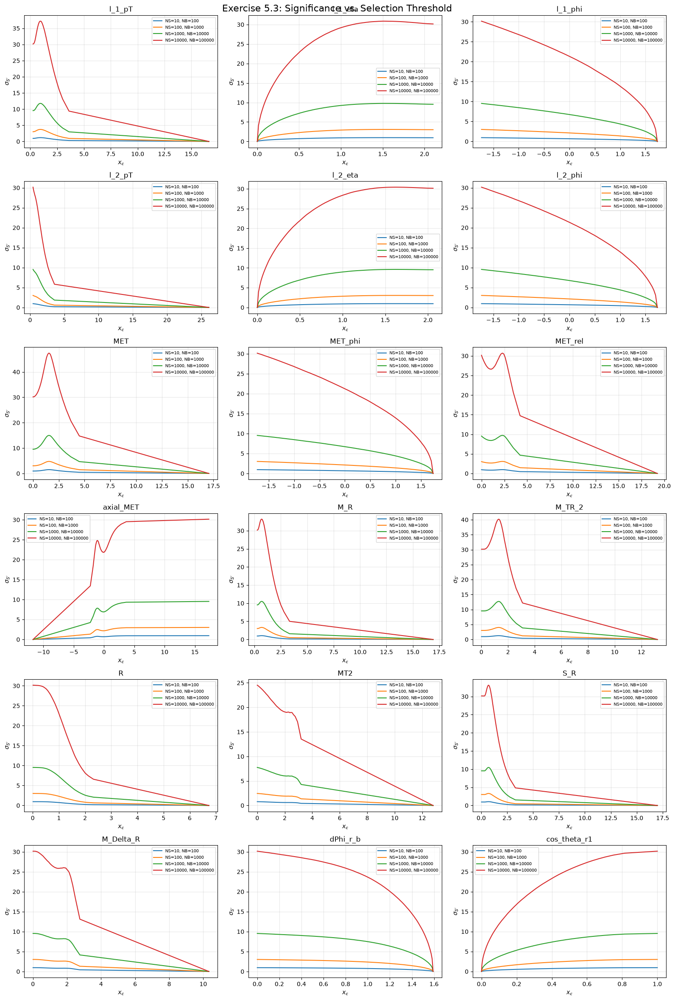

In [36]:
#5.3 
import numpy as np
import matplotlib.pyplot as plt

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

observables = VarNames[1:]

fig, axes = plt.subplots(6, 3, figsize=(16, 24))
axes = axes.flatten()

significance_results = {}

for ax, variable in zip(axes, observables):
    result = efficiency_results[variable]

    thresholds = result["thresholds"]
    tpr = result["TPR"]
    fpr = result["FPR"]

    significance_results[variable] = {}

    for NS, NB in scenarios:
        NS_selected = tpr * NS
        NB_selected = fpr * NB

        denominator = np.sqrt(NS_selected + NB_selected)

        significance = np.divide(
            NS_selected,
            denominator,
            out=np.zeros_like(NS_selected, dtype=float),
            where=denominator > 0
        )

        label = f"NS={NS}, NB={NB}"
        ax.plot(thresholds, significance, label=label)

        significance_results[variable][(NS, NB)] = significance

    ax.set_title(variable)
    ax.set_xlabel(r"$x_c$")
    ax.set_ylabel(r"$\sigma_{S'}$")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7)

fig.suptitle("Exercise 5.3: Significance vs. Selection Threshold",
             fontsize=16)
plt.tight_layout()
plt.show()


In [37]:

best_thresholds = []

for variable in observables:
    result = efficiency_results[variable]
    thresholds = result["thresholds"]

    for NS, NB in scenarios:
        significance = significance_results[variable][(NS, NB)]

        best_index = np.argmax(significance)

        best_thresholds.append({
            "Observable": variable,
            "NS": NS,
            "NB": NB,
            "Best threshold": thresholds[best_index],
            "Maximum significance": significance[best_index],
            "TPR": result["TPR"][best_index],
            "FPR": result["FPR"][best_index]
        })

best_thresholds_df = pd.DataFrame(best_thresholds)

display(
    best_thresholds_df[
        [
            "Observable",
            "NS",
            "NB",
            "Best threshold",
            "Maximum significance",
            "TPR",
            "FPR",
        ]
    ]
    .sort_values("Maximum significance", ascending=False)
    .round(4)
    .head(20)
    .reset_index(drop=True)
)


,Observable,NS,NB,Best threshold,Maximum significance,TPR,FPR
0,MET,10000,100000,1.5684,47.3840,0.3154,0.0128
1,M_TR_2,10000,100000,1.3006,40.1864,0.3951,0.0572
2,l_1_pT,10000,100000,0.9609,37.2114,0.5889,0.1916
3,M_R,10000,100000,0.6792,33.1741,0.8068,0.5107
4,S_R,10000,100000,0.7077,33.1118,0.7888,0.4886
5,l_1_eta,10000,100000,1.5062,30.8696,0.9169,0.7906
6,MET_rel,10000,100000,2.3180,30.6865,0.1450,0.0078
7,l_2_eta,10000,100000,1.6221,30.4261,0.9346,0.8502
8,M_Delta_R,10000,100000,0.0627,30.1570,0.9938,0.9866
9,l_2_pT,10000,100000,0.4286,30.1512,1.0000,1.0000


In [38]:

import numpy as np
import pandas as pd

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

summary_rows = []

for variable in VarNames[1:]:
    result = efficiency_results[variable]

    thresholds = np.asarray(result["thresholds"])
    tpr = np.asarray(result["TPR"])
    fpr = np.asarray(result["FPR"])

    for NS, NB in scenarios:
        selected_signal = tpr * NS
        selected_background = fpr * NB

        denominator = np.sqrt(selected_signal + selected_background)

        significance = np.divide(
            selected_signal,
            denominator,
            out=np.zeros_like(selected_signal, dtype=float),
            where=denominator > 0
        )

        best_idx = np.argmax(significance)

        summary_rows.append({
            "Observable": variable,
            "NS": NS,
            "NB": NB,
            "Best threshold": thresholds[best_idx],
            "Maximum significance": significance[best_idx],
            "TPR": tpr[best_idx],
            "FPR": fpr[best_idx]
        })

summary_df = pd.DataFrame(summary_rows)

display(
    summary_df.sort_values(
        ["NS", "Maximum significance"],
        ascending=[True, False]
    ).round(4).reset_index(drop=True)
)


,Observable,NS,NB,Best threshold,Maximum significance,TPR,FPR
0,MET,10,100,1.5684,1.4984,0.3154,0.0128
1,M_TR_2,10,100,1.3006,1.2708,0.3951,0.0572
2,l_1_pT,10,100,0.9609,1.1767,0.5889,0.1916
3,M_R,10,100,0.6792,1.0491,0.8068,0.5107
4,S_R,10,100,0.7077,1.0471,0.7888,0.4886
...,...,...,...,...,...,...,...
67,l_2_phi,10000,100000,-1.7342,30.1510,1.0000,1.0000
68,axial_MET,10000,100000,17.3113,30.1510,1.0000,1.0000
69,dPhi_r_b,10000,100000,0.0000,30.1510,1.0000,1.0000
70,cos_theta_r1,10000,100000,1.0000,30.1506,1.0000,1.0000


## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [39]:
#6.1
for NS, NB in scenarios:
    print(f"\nScenario: NS={NS}, NB={NB}")

    choices = (
        best_thresholds_df[
            (best_thresholds_df["NS"] == NS) &
            (best_thresholds_df["NB"] == NB)
        ]
        .sort_values("Maximum significance", ascending=False)
        .head(3)
    )

    display(choices.round(4))


Scenario: NS=10, NB=100


,Observable,NS,NB,Best threshold,Maximum significance,TPR,FPR
24,MET,10,100,1.5684,1.4984,0.3154,0.0128
44,M_TR_2,10,100,1.3006,1.2708,0.3951,0.0572
0,l_1_pT,10,100,0.9609,1.1767,0.5889,0.1916



Scenario: NS=100, NB=1000


,Observable,NS,NB,Best threshold,Maximum significance,TPR,FPR
25,MET,100,1000,1.5684,4.7384,0.3154,0.0128
45,M_TR_2,100,1000,1.3006,4.0186,0.3951,0.0572
1,l_1_pT,100,1000,0.9609,3.7211,0.5889,0.1916



Scenario: NS=1000, NB=10000


,Observable,NS,NB,Best threshold,Maximum significance,TPR,FPR
26,MET,1000,10000,1.5684,14.9841,0.3154,0.0128
46,M_TR_2,1000,10000,1.3006,12.7081,0.3951,0.0572
2,l_1_pT,1000,10000,0.9609,11.7673,0.5889,0.1916



Scenario: NS=10000, NB=100000


,Observable,NS,NB,Best threshold,Maximum significance,TPR,FPR
27,MET,10000,100000,1.5684,47.3840,0.3154,0.0128
47,M_TR_2,10000,100000,1.3006,40.1864,0.3951,0.0572
3,l_1_pT,10000,100000,0.9609,37.2114,0.5889,0.1916


In [40]:
# 6.2 Cut-flow table

selected_cuts = [
    ("MET", ">", 1.5684),
    ("M_TR_2", ">", 1.3006),
    ("l_1_pT", ">", 0.9609),
]

is_signal = (df["signal"] == 1).to_numpy()
is_background = (df["signal"] == 0).to_numpy()

keep = np.ones(len(df), dtype=bool)
rows = []

for variable, operator, threshold in selected_cuts:
    values = df[variable].to_numpy()

    if operator == ">":
        keep &= values > threshold
    else:
        keep &= values < threshold

    # Cumulative efficiencies relative to the original samples
    epsilon_S = keep[is_signal].mean()
    epsilon_B = keep[is_background].mean()

    for NS, NB in scenarios:
        NS_selected = epsilon_S * NS
        NB_selected = epsilon_B * NB

        significance = (
            NS_selected / np.sqrt(NS_selected + NB_selected)
            if NS_selected + NB_selected > 0 else 0
        )

        rows.append({
            "NS": NS,
            "NB": NB,
            "Cut applied": variable,
            "Threshold": threshold,
            "epsilon_S": epsilon_S,
            "epsilon_B": epsilon_B,
            "N'_S": NS_selected,
            "N'_B": NB_selected,
            "Significance": significance,
        })

cutflow_df = pd.DataFrame(rows)
display(cutflow_df.round(4))

,NS,NB,Cut applied,Threshold,epsilon_S,epsilon_B,N'_S,N'_B,Significance
0,10,100,MET,1.5684,0.3154,0.0128,3.1540,1.2764,1.4984
1,100,1000,MET,1.5684,0.3154,0.0128,31.5396,12.7643,4.7384
2,1000,10000,MET,1.5684,0.3154,0.0128,315.3962,127.6431,14.9843
3,10000,100000,MET,1.5684,0.3154,0.0128,3153.9619,1276.4307,47.3844
4,10,100,M_TR_2,1.3006,0.2316,0.0099,2.3163,0.9902,1.2738
5,100,1000,M_TR_2,1.3006,0.2316,0.0099,23.1634,9.9019,4.0282
6,1000,10000,M_TR_2,1.3006,0.2316,0.0099,231.6343,99.0194,12.7384
7,10000,100000,M_TR_2,1.3006,0.2316,0.0099,2316.3428,990.1941,40.2825
8,10,100,l_1_pT,0.9609,0.1851,0.0067,1.8513,0.6744,1.1649
9,100,1000,l_1_pT,0.9609,0.1851,0.0067,18.5134,6.7441,3.6838


In [41]:

# 6.3 — Correlation between observables

df_signal = df[df["signal"] == 1]
df_background = df[df["signal"] == 0]

print("Signal correlation:")
display(df_signal[["MET", "M_TR_2"]].corr().round(4))

print("Background correlation:")
display(df_background[["MET", "M_TR_2"]].corr().round(4))


Signal correlation:


,MET,M_TR_2
MET,1.0000,0.6333
M_TR_2,0.6333,1.0000


Background correlation:


,MET,M_TR_2
MET,1.0000,0.8257
M_TR_2,0.8257,1.0000


In [42]:
# Exercise 6.3: Reverse the order
# First apply M_TR_2, then MET

selected_cuts_reverse = [
    ("M_TR_2", ">", 1.3006),
    ("MET", ">", 1.5684),
]

is_signal = (df["signal"] == 1).to_numpy()
is_background = (df["signal"] == 0).to_numpy()

keep = np.ones(len(df), dtype=bool)
rows_reverse = []

for variable, operator, threshold in selected_cuts_reverse:
    values = df[variable].to_numpy()

    if operator == ">":
        keep &= values > threshold
    else:
        keep &= values < threshold

    epsilon_S = keep[is_signal].mean()
    epsilon_B = keep[is_background].mean()

    for NS, NB in scenarios:
        NS_selected = epsilon_S * NS
        NB_selected = epsilon_B * NB

        significance = (
            NS_selected / np.sqrt(NS_selected + NB_selected)
            if NS_selected + NB_selected > 0 else 0
        )

        rows_reverse.append({
            "NS": NS,
            "NB": NB,
            "Cut applied": variable,
            "Threshold": threshold,
            "epsilon_S": epsilon_S,
            "epsilon_B": epsilon_B,
            "N'_S": NS_selected,
            "N'_B": NB_selected,
            "Significance": significance,
        })

cutflow_reverse_df = pd.DataFrame(rows_reverse)
display(cutflow_reverse_df.round(4))

,NS,NB,Cut applied,Threshold,epsilon_S,epsilon_B,N'_S,N'_B,Significance
0,10,100,M_TR_2,1.3006,0.3951,0.0572,3.9515,5.7166,1.2708
1,100,1000,M_TR_2,1.3006,0.3951,0.0572,39.5149,57.1661,4.0187
2,1000,10000,M_TR_2,1.3006,0.3951,0.0572,395.1493,571.6607,12.7084
3,10000,100000,M_TR_2,1.3006,0.3951,0.0572,3951.4929,5716.6073,40.1875
4,10,100,MET,1.5684,0.2316,0.0099,2.3163,0.9902,1.2738
5,100,1000,MET,1.5684,0.2316,0.0099,23.1634,9.9019,4.0282
6,1000,10000,MET,1.5684,0.2316,0.0099,231.6343,99.0194,12.7384
7,10000,100000,MET,1.5684,0.2316,0.0099,2316.3428,990.1941,40.2825


In [43]:
# Exercise 6.3: Optimize M_TR_2 after the MET cut

met_threshold = 1.5684
mtr2_thresholds = efficiency_results["M_TR_2"]["thresholds"]

is_signal = (df["signal"] == 1).to_numpy()
is_background = (df["signal"] == 0).to_numpy()

met_values = df["MET"].to_numpy()
mtr2_values = df["M_TR_2"].to_numpy()

met_pass = met_values > met_threshold
rows_optimized = []

for threshold in mtr2_thresholds:
    final_mask = met_pass & (mtr2_values > threshold)

    epsilon_S = final_mask[is_signal].mean()
    epsilon_B = final_mask[is_background].mean()

    for NS, NB in scenarios:
        NS_selected = NS * epsilon_S
        NB_selected = NB * epsilon_B

        significance = (
            NS_selected / np.sqrt(NS_selected + NB_selected)
            if NS_selected + NB_selected > 0 else 0
        )

        rows_optimized.append({
            "NS": NS,
            "NB": NB,
            "MET threshold": met_threshold,
            "M_TR_2 threshold": threshold,
            "epsilon_S": epsilon_S,
            "epsilon_B": epsilon_B,
            "Significance": significance,
        })

optimized_df = pd.DataFrame(rows_optimized)

best_optimized = (
    optimized_df.loc[
        optimized_df.groupby(["NS", "NB"])["Significance"].idxmax()
    ]
    .sort_values(["NS", "NB"])
    .reset_index(drop=True)
)

display(best_optimized.round(4))

,NS,NB,MET threshold,M_TR_2 threshold,epsilon_S,epsilon_B,Significance
0,10,100,1.5684,0.0095,0.3154,0.0128,1.4984
1,100,1000,1.5684,0.0095,0.3154,0.0128,4.7384
2,1000,10000,1.5684,0.0095,0.3154,0.0128,14.9843
3,10000,100000,1.5684,0.0095,0.3154,0.0128,47.3844


In [44]:
# Exercise 6.3: Optimize MET after the M_TR_2 cut

mtr2_threshold = 1.3006
met_thresholds = efficiency_results["MET"]["thresholds"]

is_signal = (df["signal"] == 1).to_numpy()
is_background = (df["signal"] == 0).to_numpy()

met_values = df["MET"].to_numpy()
mtr2_values = df["M_TR_2"].to_numpy()

mtr2_pass = mtr2_values > mtr2_threshold
rows_reverse_optimized = []

for threshold in met_thresholds:
    final_mask = mtr2_pass & (met_values > threshold)

    epsilon_S = final_mask[is_signal].mean()
    epsilon_B = final_mask[is_background].mean()

    for NS, NB in scenarios:
        NS_selected = NS * epsilon_S
        NB_selected = NB * epsilon_B

        significance = (
            NS_selected / np.sqrt(NS_selected + NB_selected)
            if NS_selected + NB_selected > 0 else 0
        )

        rows_reverse_optimized.append({
            "NS": NS,
            "NB": NB,
            "M_TR_2 threshold": mtr2_threshold,
            "MET threshold": threshold,
            "epsilon_S": epsilon_S,
            "epsilon_B": epsilon_B,
            "Significance": significance,
        })

reverse_optimized_df = pd.DataFrame(rows_reverse_optimized)

best_reverse_optimized = (
    reverse_optimized_df.loc[
        reverse_optimized_df.groupby(["NS", "NB"])["Significance"].idxmax()
    ]
    .sort_values(["NS", "NB"])
    .reset_index(drop=True)
)

display(best_reverse_optimized.round(4))

,NS,NB,M_TR_2 threshold,MET threshold,epsilon_S,epsilon_B,Significance
0,10,100,1.3006,1.429,0.2648,0.0162,1.2818
1,100,1000,1.3006,1.429,0.2648,0.0162,4.0534
2,1000,10000,1.3006,1.429,0.2648,0.0162,12.8179
3,10000,100000,1.3006,1.429,0.2648,0.0162,40.5337


The correlation matrices show a positive correlation between MET and M_TR_2 for both signal (0.6333) and background (0.8257), with a stronger correlation for background. This suggests that the two observables may provide overlapping information, especially for background events. When optimizing the second observable after applying a cut on the first, the results depend on which observable is fixed first. Optimizing M_TR_2 after MET produced a higher reported maximum significance (47.3844 for \(N_S=10{,}000\) and \(N_B=100{,}000\)) than optimizing MET after M_TR_2 (40.5337). The first result used a very low M_TR_2 threshold, however, so further checking is needed to confirm that the threshold scan is meaningful.

## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



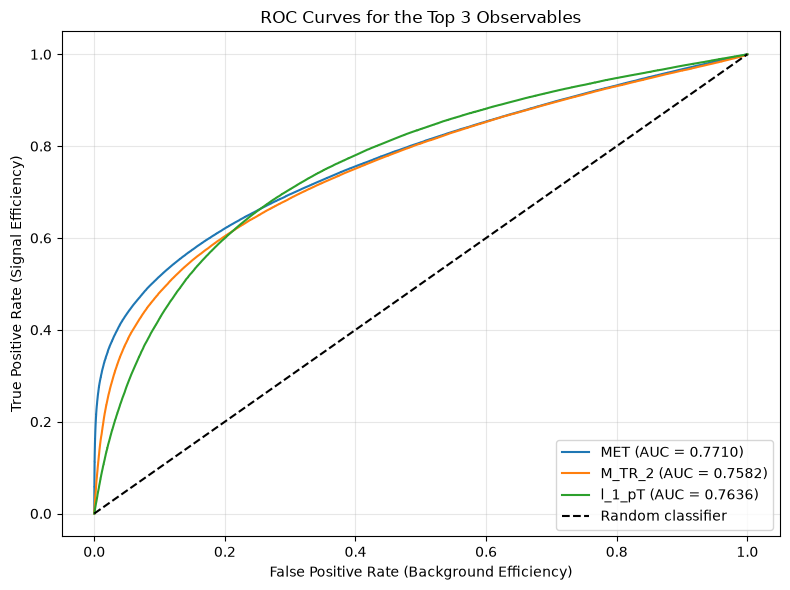

In [45]:

# Exercise 7.1 — ROC curves and AUC

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc

top_3_observables = ["MET", "M_TR_2", "l_1_pT"]

y_true = (df["signal"] == 1).to_numpy()

plt.figure(figsize=(8, 6))

for variable in top_3_observables:
    scores = df[variable].to_numpy()

    valid = np.isfinite(scores)
    y = y_true[valid]
    scores = scores[valid]

    fpr, tpr, thresholds = roc_curve(y, scores)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        label=f"{variable} (AUC = {roc_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate (Background Efficiency)")
plt.ylabel("True Positive Rate (Signal Efficiency)")
plt.title("ROC Curves for the Top 3 Observables")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [46]:

# Exercise 7.2 — Reusable ROC plotting function

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc

def plot_roc_curves(df, observables, title="ROC Curves",
                    selection=None, directions=None):
    """
    Plot ROC curves and calculate AUC for selected observables.

    df: DataFrame containing observables and the signal column
    observables: list of observable names
    selection: optional Boolean mask selecting events
    directions: optional dictionary; use ">" if larger values
                favor signal, or "<" if smaller values favor signal
    """

    if selection is None:
        selection = np.ones(len(df), dtype=bool)

    if directions is None:
        directions = {}

    y_all = (df["signal"] == 1).to_numpy()
    plt.figure(figsize=(8, 6))

    for variable in observables:
        scores_all = df[variable].to_numpy()

        valid = selection & np.isfinite(scores_all)
        y = y_all[valid]
        scores = scores_all[valid]

        if directions.get(variable, ">") == "<":
            scores = -scores

        fpr, tpr, _ = roc_curve(y, scores)
        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr, tpr,
            label=f"{variable} (AUC = {roc_auc:.4f})"
        )

    plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


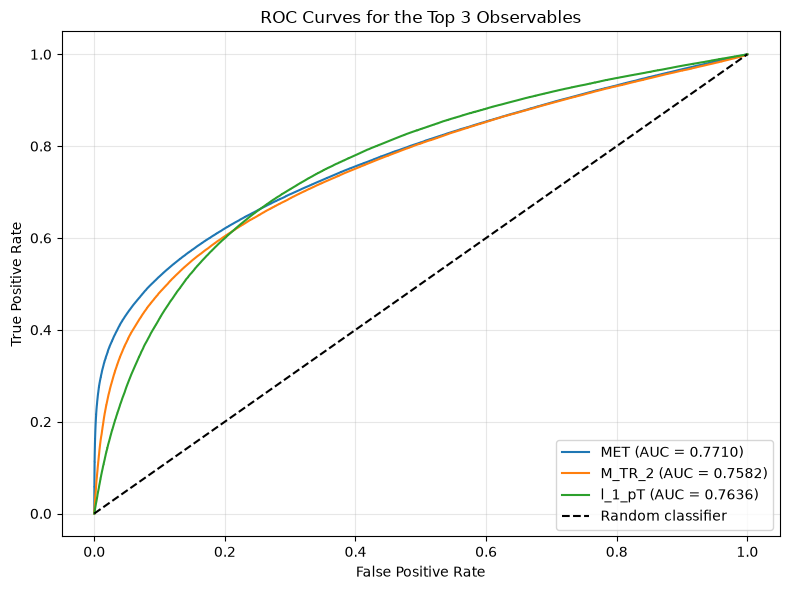

In [47]:

plot_roc_curves(
    df,
    ["MET", "M_TR_2", "l_1_pT"],
    title="ROC Curves for the Top 3 Observables"
)


In [48]:

# Exercise 7.2 update — ROC plotting function

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

def roc_plot(data, observables, conditions=None,
             label_col="signal", title="ROC curves"):

    y = data[label_col].to_numpy().astype(int)
    fig, ax = plt.subplots(figsize=(7, 6))
    aucs = {}

    if conditions is None:
        for var in observables:
            score = data[var].to_numpy()
            valid = np.isfinite(score)

            fpr, tpr, _ = roc_curve(y[valid], score[valid])
            area = auc(fpr, tpr)

            if area < 0.5:
                fpr, tpr, _ = roc_curve(y[valid], -score[valid])
                area = auc(fpr, tpr)

            ax.plot(fpr, tpr, label=f"{var} (AUC={area:.3f})")
            aucs[var] = area

    else:
        keep = np.ones(len(data), dtype=bool)

        for var, ct, threshold, center in conditions:
            values = data[var].to_numpy()

            if ct == ">":
                keep &= values > threshold
            elif ct == "<":
                keep &= values < threshold
            else:
                raise ValueError("Cut type must be '>' or '<'.")

            valid = np.isfinite(values)
            y_valid = y[valid]
            keep_valid = keep[valid]

            fpr = np.array([
                0,
                (~keep_valid[y_valid == 0]).mean(),
                1
            ])
            tpr = np.array([
                0,
                keep_valid[y_valid == 1].mean(),
                1
            ])

            ax.plot(fpr, tpr, marker="o", label=f"Through {var}")

    ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax.set_xlabel("False Positive Rate (Background Efficiency)")
    ax.set_ylabel("True Positive Rate (Signal Efficiency)")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    return fig, aucs


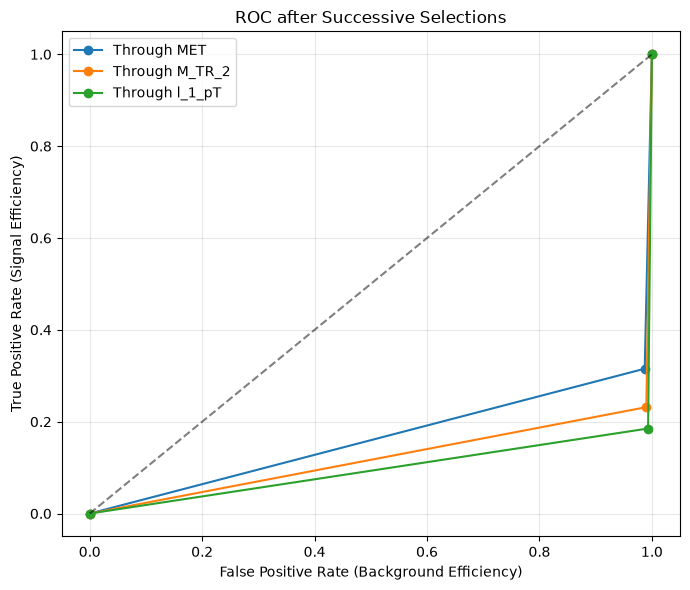

In [49]:

# Exercise 7.3 — ROC operating points after each cumulative cut

conditions = [
    ("MET", ">", 1.5684, None),
    ("M_TR_2", ">", 1.3006, None),
    ("l_1_pT", ">", 0.9609, None),
]

roc_plot(
    df,
    observables=[],
    conditions=conditions,
    title="ROC after Successive Selections"
)

plt.show()


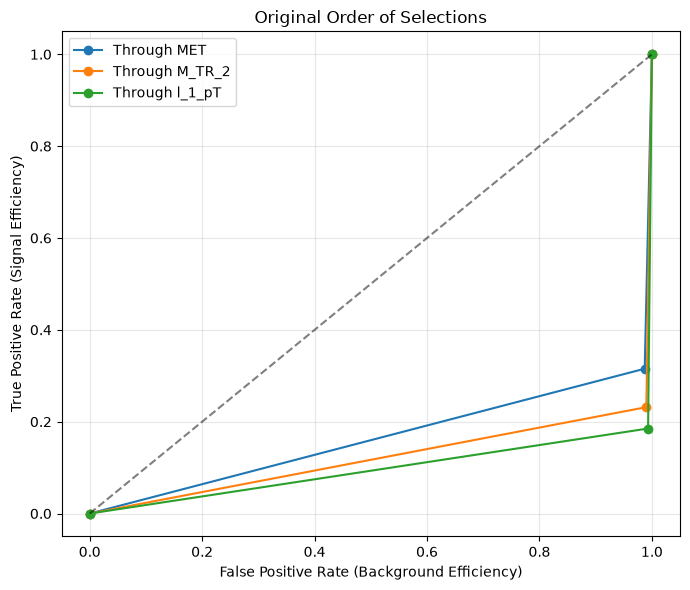

In [50]:

# Exercise 7.4 — Original order

original_order = [
    ("MET", ">", 1.5684, None),
    ("M_TR_2", ">", 1.3006, None),
    ("l_1_pT", ">", 0.9609, None),
]

roc_plot(
    df,
    observables=[],
    conditions=original_order,
    title="Original Order of Selections"
)

plt.show()


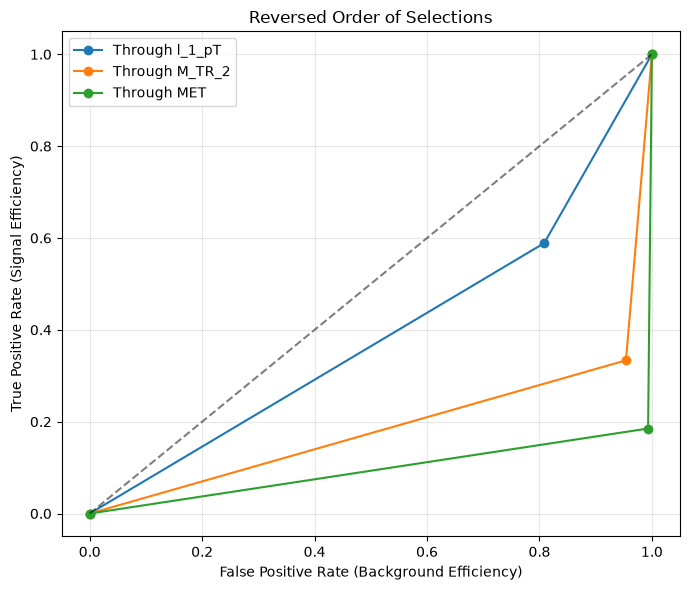

In [51]:

# Exercise 7.4 — Reversed order

reversed_order = list(reversed(original_order))

roc_plot(
    df,
    observables=[],
    conditions=reversed_order,
    title="Reversed Order of Selections"
)

plt.show()


In [52]:

# Compare cumulative selections in both orders

def compare_cut_orders(data, conditions):
    keep = np.ones(len(data), dtype=bool)
    signal = data["signal"].to_numpy() == 1
    background = data["signal"].to_numpy() == 0

    rows = []

    for var, operator, threshold, center in conditions:
        values = data[var].to_numpy()

        if operator == ">":
            keep &= values > threshold
        else:
            keep &= values < threshold

        rows.append({
            "Cut applied": f"{var} {operator} {threshold}",
            "Signal remaining": int(np.sum(keep & signal)),
            "Background remaining": int(np.sum(keep & background)),
            "Signal efficiency": keep[signal].mean(),
            "Background efficiency": keep[background].mean(),
        })

    return pd.DataFrame(rows)

print("Original order:")
display(compare_cut_orders(df, original_order).round(4))

print("Reversed order:")
display(compare_cut_orders(df, reversed_order).round(4))


Original order:


,Cut applied,Signal remaining,Background remaining,Signal efficiency,Background efficiency
0,MET > 1.5684,72303,3456,0.3154,0.0128
1,M_TR_2 > 1.3006,53101,2681,0.2316,0.0099
2,l_1_pT > 0.9609,42441,1826,0.1851,0.0067


Reversed order:


,Cut applied,Signal remaining,Background remaining,Signal efficiency,Background efficiency
0,l_1_pT > 0.9609,135000,51864,0.5889,0.1916
1,M_TR_2 > 1.3006,76467,12487,0.3336,0.0461
2,MET > 1.5684,42441,1826,0.1851,0.0067


Changing the order of successive selections changes the intermediate cut-flow results because each cut is applied to the events that survived the previous cuts. However, when the same fixed cuts are all applied, the final selected event sample should be identical regardless of the order. Therefore, the final signal efficiency, background efficiency, and significance should also be the same, apart from possible numerical rounding.

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

In [53]:

# Exercise 8.1 — Prepare signal and background data

import numpy as np
import pandas as pd

observables = VarNames[1:]

X_signal = df.loc[df["signal"] == 1, observables].to_numpy(dtype=float)
X_background = df.loc[df["signal"] == 0, observables].to_numpy(dtype=float)

X_signal = X_signal[np.isfinite(X_signal).all(axis=1)]
X_background = X_background[np.isfinite(X_background).all(axis=1)]

print("Signal data shape:", X_signal.shape)
print("Background data shape:", X_background.shape)
print("Number of observables:", len(observables))


Signal data shape: (229245, 18)
Background data shape: (270755, 18)
Number of observables: 18


In [54]:

# Compute class mean vectors

m1 = np.mean(X_signal, axis=0)
m2 = np.mean(X_background, axis=0)

mean_difference = m2 - m1
S_B = np.outer(mean_difference, mean_difference)

signal_centered = X_signal - m1
background_centered = X_background - m2

S_W = (
    signal_centered.T @ signal_centered
    + background_centered.T @ background_centered
)

print("Signal mean vector (m1):")
print(m1)

print("\nBackground mean vector (m2):")
print(m2)

print("\nBetween-class matrix S_B:")
print(S_B)

print("\nWithin-class matrix S_W:")
print(S_W)


Signal mean vector (m1):
[ 1.29107791e+00  8.23504357e-04 -1.52423079e-03  1.13866797e+00
  2.48689227e-03  4.92614318e-05  1.41838122e+00 -4.70486145e-04
  1.27516872e+00  8.93141690e-02  1.18365116e+00  1.26885824e+00
  1.05635238e+00  1.07469364e+00  1.17502322e+00  1.18602209e+00
  1.01461743e+00  2.82416774e-01]

Background mean vector (m2):
[ 7.54449334e-01 -3.16910651e-05 -2.39534994e-03  8.81229832e-01
 -3.84144703e-04 -6.32952625e-04  6.47901679e-01  7.15842902e-04
  7.69910060e-01 -6.99500081e-02  8.43878562e-01  7.72131710e-01
  9.53259216e-01  9.37201138e-01  8.50326037e-01  8.42923556e-01
  9.85909142e-01  1.76891080e-01]

Between-class matrix S_B:
[[ 2.87970231e-01  4.58922304e-04  4.67467434e-04  1.38148662e-01
   1.54068049e-03  3.66095560e-04  4.13461344e-01 -6.36618070e-04
   2.71136238e-01  8.54657090e-02  1.82331687e-01  2.66557653e-01
   5.53227373e-02  7.37824064e-02  1.74241790e-01  1.84116478e-01
   1.54056891e-02  5.66281031e-02]
 [ 4.58922304e-04  7.31359210e-

In [55]:

# Exercise 8.2 — Calculate Fisher linear discriminant coefficients

w = np.linalg.solve(S_W, m2 - m1)

print("Linear discriminant coefficients:")
print(w)


Linear discriminant coefficients:
[-2.26832982e-06 -5.63688439e-09 -2.10423856e-09 -9.95582982e-07
 -3.48452234e-09 -2.70762588e-09 -1.65185357e-06 -2.74241844e-09
 -1.39723282e-07 -2.64205675e-07  2.72149250e-07 -1.48465692e-07
  2.11167032e-06  3.24040633e-07  1.81173242e-06 -1.69348122e-06
  7.50902836e-08 -5.06860437e-06]


In [56]:

# Calculate F = w^T x for each event

F_signal = X_signal @ w
F_background = X_background @ w

print("Signal scores:", F_signal.shape)
print("Background scores:", F_background.shape)


Signal scores: (229245,)
Background scores: (270755,)


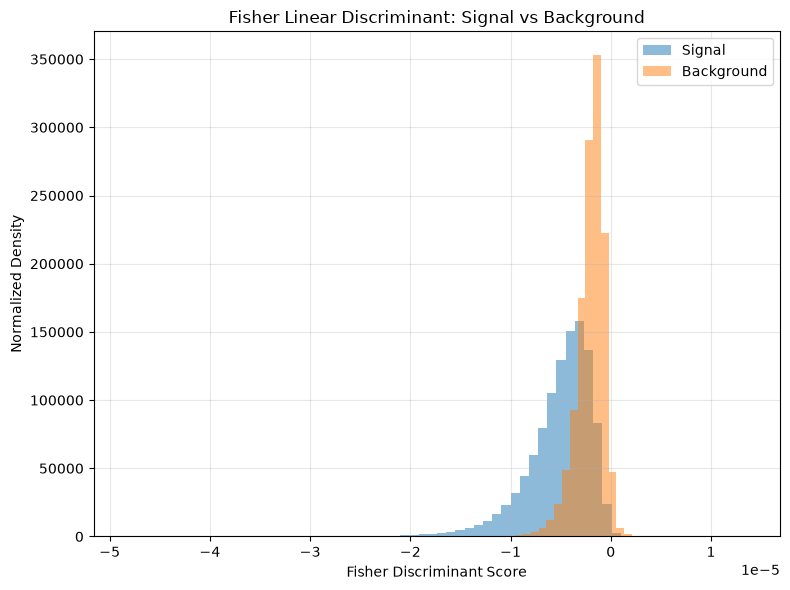

In [57]:

# Compare signal and background distributions

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.hist(
    F_signal,
    bins=60,
    density=True,
    alpha=0.5,
    label="Signal"
)

plt.hist(
    F_background,
    bins=60,
    density=True,
    alpha=0.5,
    label="Background"
)

plt.xlabel("Fisher Discriminant Score")
plt.ylabel("Normalized Density")
plt.title("Fisher Linear Discriminant: Signal vs Background")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Fisher discriminant AUC: 0.8375


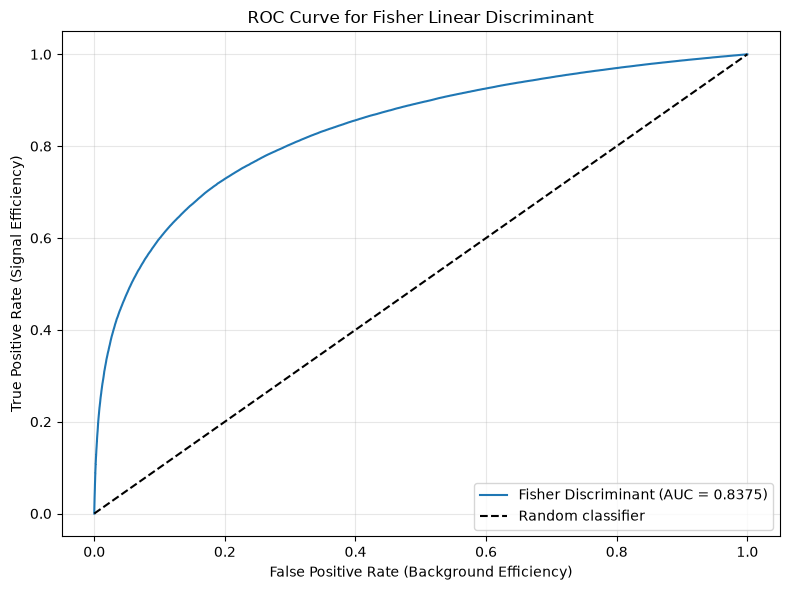

In [58]:

# Exercise 8.3 — ROC curve for Fisher's linear discriminant

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

F = np.concatenate([F_signal, F_background])

y_true = np.concatenate([
    np.ones(len(F_signal), dtype=int),
    np.zeros(len(F_background), dtype=int)
])

fpr, tpr, thresholds = roc_curve(y_true, F)

roc_auc = auc(fpr, tpr)

if roc_auc < 0.5:
    fpr, tpr, thresholds = roc_curve(y_true, -F)
    roc_auc = auc(fpr, tpr)

print(f"Fisher discriminant AUC: {roc_auc:.4f}")

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Fisher Discriminant (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate (Background Efficiency)")
plt.ylabel("True Positive Rate (Signal Efficiency)")
plt.title("ROC Curve for Fisher Linear Discriminant")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



In [59]:


# Exercise 8.4 — Maximum significance for each scenario

from sklearn.metrics import roc_curve, auc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

F = np.concatenate([F_signal, F_background])

y_true = np.concatenate([
    np.ones(len(F_signal), dtype=int),
    np.zeros(len(F_background), dtype=int)
])

fpr, tpr, thresholds = roc_curve(y_true, F)

if auc(fpr, tpr) < 0.5:
    F = -F
    fpr, tpr, thresholds = roc_curve(y_true, F)

results_84 = []

for NS, NB in scenarios:
    NS_selected = tpr * NS
    NB_selected = fpr * NB

    denominator = np.sqrt(NS_selected + NB_selected)

    significance = np.divide(
        NS_selected,
        denominator,
        out=np.zeros_like(NS_selected),
        where=denominator > 0
    )

    # Only consider finite thresholds when choosing the maximum
    finite = np.isfinite(thresholds)
    valid_indices = np.where(finite)[0]

    best_index = valid_indices[
        np.argmax(significance[finite])
    ]

    results_84.append({
        "NS": NS,
        "NB": NB,
        "Maximum significance": significance[best_index],
        "Best threshold": thresholds[best_index],
        "Signal efficiency": tpr[best_index],
        "Background efficiency": fpr[best_index],
        "Selected signal": NS_selected[best_index],
        "Selected background": NB_selected[best_index]
    })

results_84_df = pd.DataFrame(results_84)

display(results_84_df.round(4))


,NS,NB,Maximum significance,Best threshold,Signal efficiency,Background efficiency,Selected signal,Selected background
0,10,100,1.5326,0.0,0.4916,0.0537,4.9163,5.3742
1,100,1000,4.8464,0.0,0.4916,0.0537,49.1631,53.7423
2,1000,10000,15.3257,0.0,0.4916,0.0537,491.6312,537.4231
3,10000,100000,48.4641,0.0,0.4916,0.0537,4916.3122,5374.2313


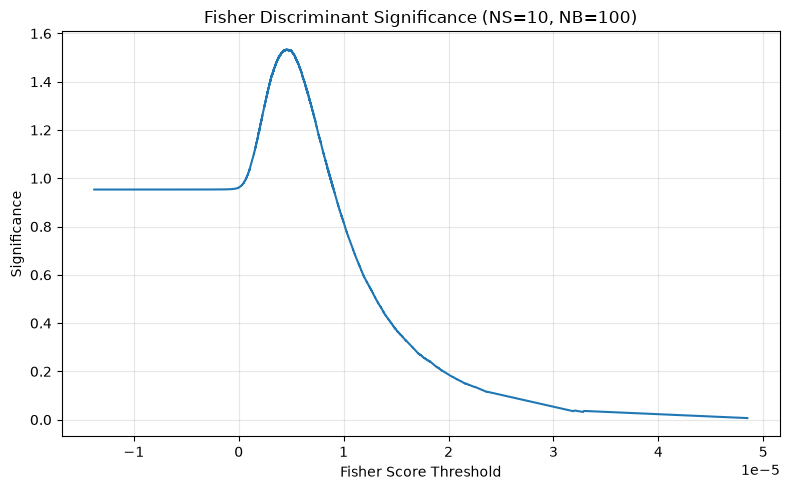

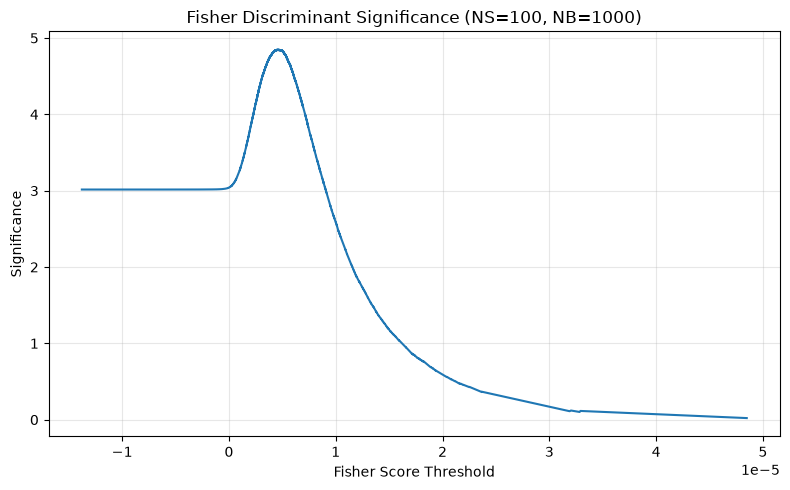

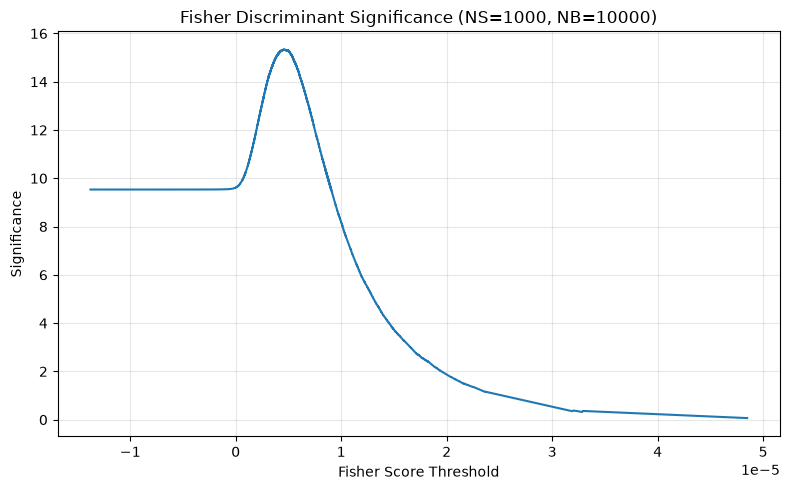

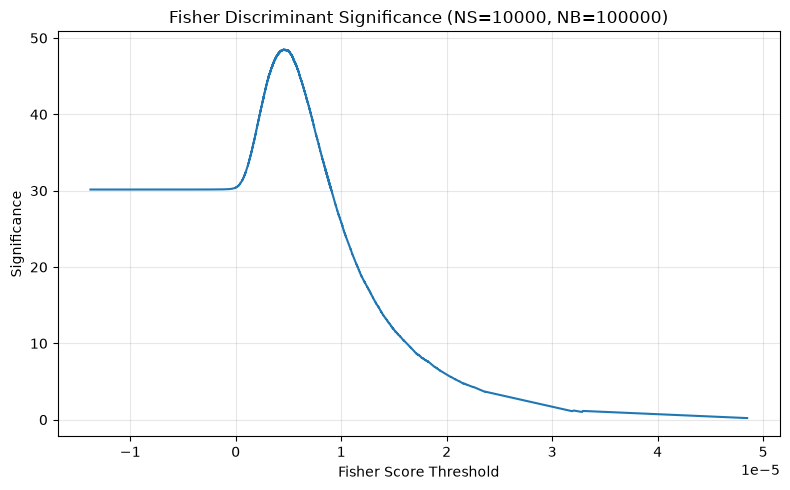

In [60]:

# Plot significance versus threshold for each scenario

for NS, NB in scenarios:
    NS_selected = tpr * NS
    NB_selected = fpr * NB

    denominator = np.sqrt(NS_selected + NB_selected)

    significance = np.divide(
        NS_selected,
        denominator,
        out=np.zeros_like(NS_selected),
        where=denominator > 0
    )

    valid = np.isfinite(thresholds)

    plt.figure(figsize=(8, 5))
    plt.plot(thresholds[valid], significance[valid])
    plt.xlabel("Fisher Score Threshold")
    plt.ylabel("Significance")
    plt.title(f"Fisher Discriminant Significance (NS={NS}, NB={NB})")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


For Exercise 8.4, I calculated the signal and background efficiencies at different thresholds of the Fisher linear discriminant score. For each scenario from Exercise 5, I used these efficiencies to estimate the selected signal and background yields and calculated the significance using \(Z=N'_S/\sqrt{N'_S+N'_B}\). The maximum significance is the largest value obtained across the tested thresholds for each scenario.